# 04 — Multivariate visualisation

Relationships between film attributes and the two success measures:
commercial (revenue, ROI) and critical (audience rating). All financial
analysis uses the complete-case sample — budget and revenue known and
plausible, released by 2025 — with the sample size on every figure.
`ROI = revenue / budget` is computed here ad hoc for plotting; Chapter 4
formalises it as an engineered feature. ROI is a ratio of same-year
dollars, so it is identical for nominal and deflated figures.

Every correlation is reported with its p-value and n, and written to
`report/stats/ch03_multivariate.json`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats as sps

from src.load import load_interim
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, fmt_money_m, fmt_p, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_interim("movies_clean")
fin = df[df["has_financials"] & ~df["is_future"]].copy()
for c in ["Budget", "Worldwide_Revenue"]:
    fin[c] = fin[c].astype("float64")
fin["roi"] = fin["Worldwide_Revenue"] / fin["Budget"]
fin["log_budget"] = np.log10(fin["Budget"])
fin["log_revenue"] = np.log10(fin["Worldwide_Revenue"])
stats["n_financial"] = len(fin)
print(f"financial sample: {len(fin):,}")

financial sample: 6,560


## Budget vs revenue, log-log, with the break-even line

The dashed line is `revenue = budget`: films below it did not recoup their
production budget from worldwide gross (marketing costs would push the
true break-even line higher still — marketing spend is not in the data).

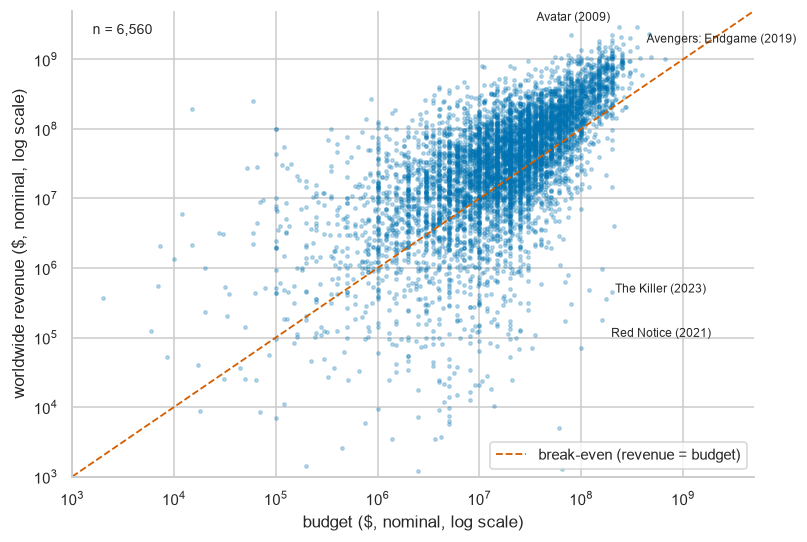

Pearson r (log-log) = 0.638 (p = 0.0e+00), Spearman r = 0.675, n = 6,560
films below break-even on production budget alone: 26.5%


In [2]:
r_p, p_p = sps.pearsonr(fin["log_budget"], fin["log_revenue"])
r_s, p_s = sps.spearmanr(fin["Budget"], fin["Worldwide_Revenue"])
below = (fin["roi"] < 1).mean() * 100
stats.update(
    budget_revenue_pearson_loglog=round(float(r_p), 3),
    budget_revenue_pearson_p=float(p_p),
    budget_revenue_spearman=round(float(r_s), 3),
    pct_below_breakeven=round(float(below), 1),
)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(fin["Budget"], fin["Worldwide_Revenue"], s=5, alpha=0.25)
lims = [1e3, 5e9]
ax.plot(lims, lims, ls="--", color="C3", lw=1.2, label="break-even (revenue = budget)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(*lims)
ax.set_ylim(*lims)
ax.set_xlabel("budget ($, nominal, log scale)")
ax.set_ylabel("worldwide revenue ($, nominal, log scale)")

# annotate the extremes by title instead of dropping them
top_rev = fin.nlargest(2, "Worldwide_Revenue")
# sorted by revenue so the lower point's label goes below it and the higher one's above
flops = fin[fin["Budget"] > 1e8].nsmallest(2, "roi").sort_values("Worldwide_Revenue")
# (offset in points, horizontal alignment) per label, so neighbours don't collide
placement = [((-6, 4), "right"), ((6, -10), "left"), ((6, -11), "left"), ((6, 4), "left")]
for (_, r), (off, ha) in zip(pd.concat([top_rev, flops]).iterrows(), placement):
    ax.annotate(
        f'{r["Title"]} ({int(r["Release_Year"])})',
        xy=(r["Budget"], r["Worldwide_Revenue"]),
        xytext=off, textcoords="offset points", fontsize=8, ha=ha,
    )
ax.annotate(f"n = {len(fin):,}", xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
ax.legend(loc="lower right")
save_fig(fig, "fig3_6_budget_vs_revenue")
# Round-number budgets (vertical stripes in the plot): share of budgets that are a
# whole multiple of $1M — reporting heaping, a data-quality signal
stats["pct_budgets_round_million"] = round(float((fin["Budget"] % 1_000_000 == 0).mean()) * 100, 1)
stats["annotated_titles"] = [f'{r["Title"]} ({int(r["Release_Year"])})'
                             for _, r in pd.concat([top_rev, flops]).iterrows()]
for i, (_, r) in enumerate(flops.iterrows(), start=1):
    stats[f"flop_title_{['a', 'b'][i - 1]}"] = f'{r["Title"]} ({int(r["Release_Year"])})'
    stats[f"flop_revenue_{['a', 'b'][i - 1]}"] = float(r["Worldwide_Revenue"])
    stats[f"flop_budget_{['a', 'b'][i - 1]}"] = float(r["Budget"])
for i, (_, r) in enumerate(top_rev.iterrows(), start=1):
    stats[f"top_title_{['a', 'b'][i - 1]}"] = f'{r["Title"]} ({int(r["Release_Year"])})'
plt.show()
print(f"Pearson r (log-log) = {r_p:.3f} (p = {p_p:.1e}), Spearman r = {r_s:.3f}, n = {len(fin):,}")
print(f"films below break-even on production budget alone: {below:.1f}%")

## ROI by genre — and the budget distribution behind it

Multi-label genres are exploded, so a film counts in each of its genres.
Genres with fewer than 100 financially-documented films are dropped from
this plot. ROI is on a log scale; the right panel shows each genre's
budget distribution, because genre ROI and genre budget are entangled
(Simpson's paradox risk) — horror's famous ratios sit on the smallest
denominators in the table, so medians and means must be read together.

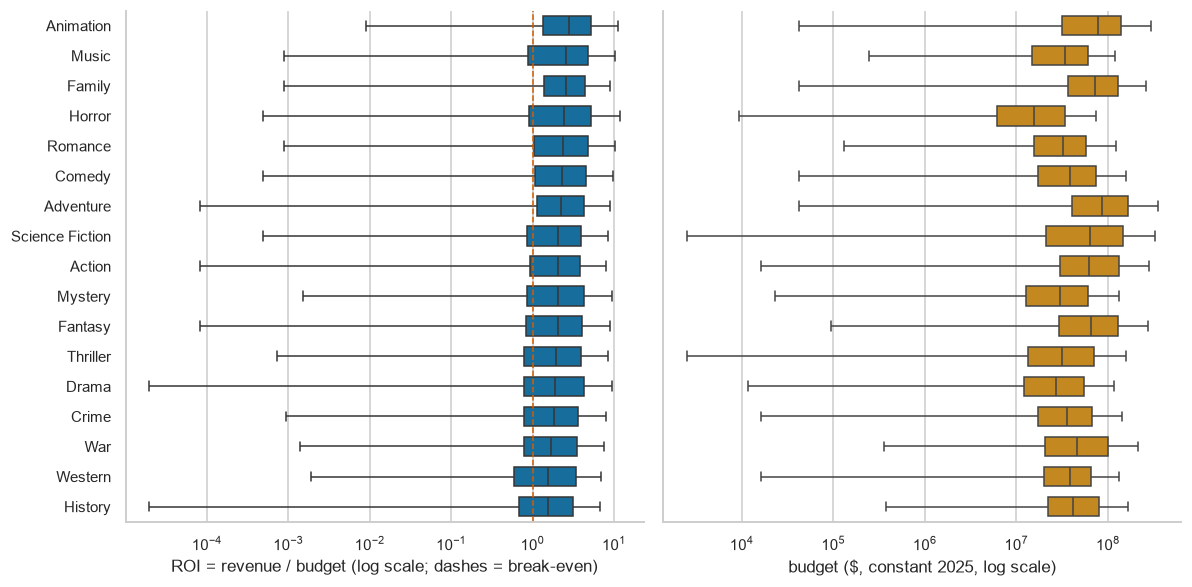

,n,median_roi,mean_roi,median_budget_2025
Genre,,,,
Animation,433,2.83,6.84,76973492.31
Music,173,2.58,5.53,33761164.29
Family,714,2.56,5.06,71819954.32
Horror,957,2.43,26.39,15394698.46
Romance,1083,2.34,4.74,31940109.96
Comedy,2266,2.30,4.83,38030827.25
Adventure,1266,2.26,4.35,85297245.93
Science Fiction,861,2.08,4.81,63045288.23
Action,1664,2.06,4.63,62331350.77


In [3]:
g = fin.copy()
g["Genre"] = g["Genres"].str.split(",")
g = g.explode("Genre")
g["Genre"] = g["Genre"].str.strip()
counts = g["Genre"].value_counts()
keep = counts[counts >= 100].index
g = g[g["Genre"].isin(keep)]
order = g.groupby("Genre")["roi"].median().sort_values(ascending=False).index

roi_table = (
    g.groupby("Genre")
    .agg(n=("roi", "size"), median_roi=("roi", "median"), mean_roi=("roi", "mean"),
         median_budget_2025=("Budget_2025usd", "median"))
    .loc[order]
    .round(2)
)
stats["genre_top_median_roi"] = str(order[0])
stats["genre_top_median_roi_value"] = float(roi_table.iloc[0]["median_roi"])
stats["genre_bottom_median_roi"] = str(order[-1])
stats["genre_min_n"] = 100

# The outliers that explode the Horror/Mystery means, named rather than hidden
top_roi = fin.nlargest(2, "roi")
stats["roi_outliers"] = [
    f'{r["Title"]} ({int(r["Release_Year"])}): ROI {r["roi"]:,.0f} on ${r["Budget"]:,.0f}'
    for _, r in top_roi.iterrows()
]
stats["horror_mean_roi"] = float(roi_table.loc["Horror", "mean_roi"])
stats["horror_median_roi"] = float(roi_table.loc["Horror", "median_roi"])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
sns.boxplot(data=g, y="Genre", x="roi", order=order, ax=axes[0],
            showfliers=False, color="C0", width=0.65)
axes[0].set_xscale("log")
axes[0].axvline(1, ls="--", color="C3", lw=1)
axes[0].set_xlabel("ROI = revenue / budget (log scale; dashes = break-even)")
axes[0].set_ylabel(None)
sns.boxplot(data=g, y="Genre", x="Budget_2025usd", order=order, ax=axes[1],
            showfliers=False, color="C1", width=0.65)
axes[1].set_xscale("log")
axes[1].set_xlabel("budget ($, constant 2025, log scale)")
axes[1].set_ylabel(None)
fig.tight_layout()
save_fig(fig, "fig3_7_roi_by_genre")
plt.show()

roi_tex = roi_table.reset_index().rename(columns={"Genre": "genre"})
roi_tex = pd.DataFrame(
    {
        "genre": roi_tex["genre"],
        "n": roi_tex["n"].map(fmt_int),
        "median ROI": roi_tex["median_roi"].map(lambda v: f"{v:.2f}"),
        "mean ROI": roi_tex["mean_roi"].map(lambda v: f"{v:.2f}"),
        "median budget (2025 \\$M)": roi_tex["median_budget_2025"].map(fmt_money_m),
    }
)
write_table(roi_tex, "tab3_1_roi_by_genre")
stats["animation_median_budget_m"] = round(float(roi_table.loc["Animation", "median_budget_2025"]) / 1e6, 1)
stats["horror_median_budget_m"] = round(float(roi_table.loc["Horror", "median_budget_2025"]) / 1e6, 1)
stats["mystery_mean_roi"] = float(roi_table.loc["Mystery", "mean_roi"])
stats["mystery_median_roi"] = float(roi_table.loc["Mystery", "median_roi"])
stats["history_median_roi"] = float(roi_table.loc["History", "median_roi"])
roi_table

**A result that contradicts the folk wisdom.** Horror does *not* top the
median ROI table — **Animation** (2.83), Music and Family do, despite
animation carrying one of the *largest* median budgets. Horror is
mid-table by median (2.43) but has by far the most extreme mean (26.4 vs
a 2.43 median), and Mystery's mean is even wilder (32.7): both are
inflated by the same two micro-budget outliers, *Paranormal Activity*
(ROI ≈ 12,890 on a \$15k budget) and *The Blair Witch Project*
(ROI ≈ 4,144), each tagged Horror **and** Mystery. The "horror is the
best bet" story is a mean artifact; the typical horror film clears a low
bar on a tiny denominator. Mean ROI is far above median ROI in every
genre, which is why the table reports both.

## Rating vs revenue

Critical and commercial success are expected to be only weakly related —
that weakness is itself a finding.

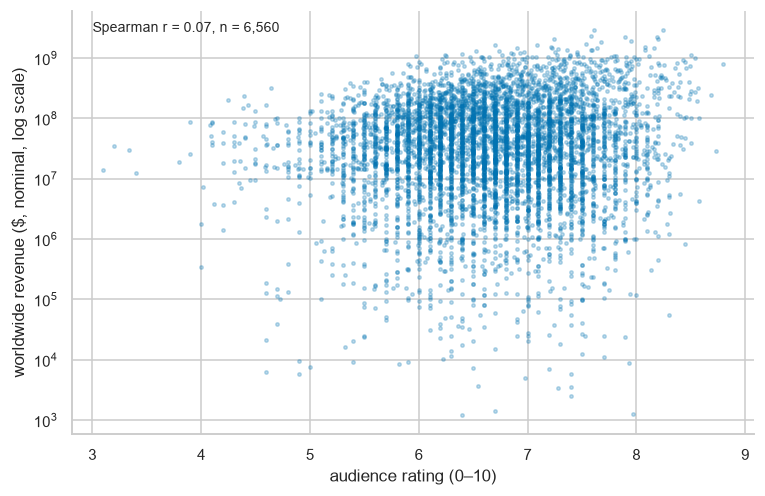

Spearman r = 0.074 (p = 2.1e-09), n = 6,560


In [4]:
r_s2, p_s2 = sps.spearmanr(fin["Audience_Rating"], fin["Worldwide_Revenue"])
stats.update(rating_revenue_spearman=round(float(r_s2), 3), rating_revenue_p=float(p_s2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fin["Audience_Rating"], fin["Worldwide_Revenue"], s=5, alpha=0.25)
ax.set_yscale("log")
ax.set_xlabel("audience rating (0–10)")
ax.set_ylabel("worldwide revenue ($, nominal, log scale)")
ax.annotate(f"Spearman r = {r_s2:.2f}, n = {len(fin):,}",
            xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
save_fig(fig, "fig3_8_rating_vs_revenue")
plt.show()
print(f"Spearman r = {r_s2:.3f} (p = {p_s2:.1e}), n = {len(fin):,}")

## Release month vs revenue

Tests the folk wisdom of the summer and holiday windows. Months are
compared with a Kruskal-Wallis test (revenue is far from normal), and the
figure shows the median with the interquartile range rather than a mean.

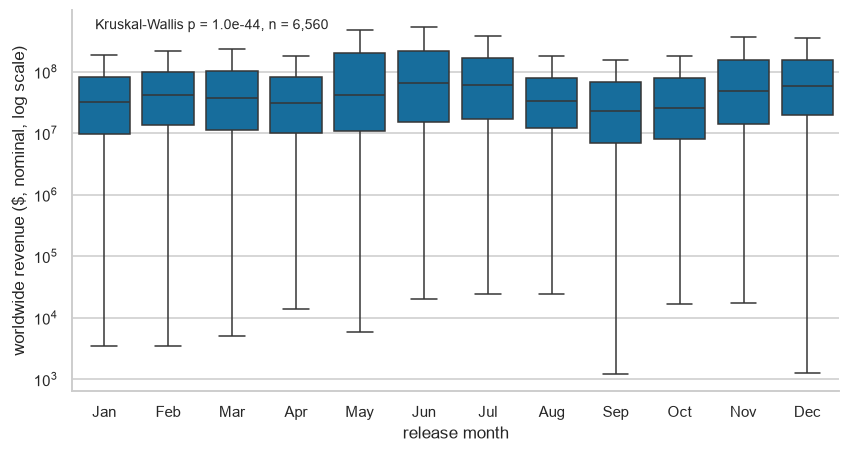

month
1     32.5
2     41.0
3     37.7
4     30.5
5     42.0
6     65.4
7     60.0
8     33.6
9     22.5
10    25.8
11    47.6
12    58.5
Name: median revenue ($M), dtype: float64

In [5]:
m = fin.dropna(subset=["Release_Date"]).copy()
m["month"] = m["Release_Date"].dt.month
kw = sps.kruskal(*[grp["Worldwide_Revenue"].values for _, grp in m.groupby("month")])
med = m.groupby("month")["Worldwide_Revenue"].median()
stats.update(
    month_kruskal_p=float(kw.pvalue),
    best_month=int(med.idxmax()),
    best_month_median=float(med.max()),
    worst_month=int(med.idxmin()),
    worst_month_median=float(med.min()),
)

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=m, x="month", y="Worldwide_Revenue", showfliers=False, color="C0", ax=ax)
ax.set_yscale("log")
ax.set_xticks(range(12), month_names)
ax.set_xlabel("release month")
ax.set_ylabel("worldwide revenue ($, nominal, log scale)")
ax.annotate(f"Kruskal-Wallis p = {kw.pvalue:.1e}, n = {len(m):,}",
            xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
save_fig(fig, "fig3_9_month_vs_revenue")
plt.show()
stats["n_month"] = len(m)
stats["july_median"] = float(med.loc[7])
stats["december_median"] = float(med.loc[12])
stats["june_to_september_ratio"] = round(float(med.loc[6] / med.loc[9]), 2)
(med / 1e6).round(1).rename("median revenue ($M)")

## Correlation heatmap

Spearman rank correlations — the financial variables are too skewed for
Pearson to be meaningful on raw dollars. Computed on the financial sample
so every cell shares the same n.

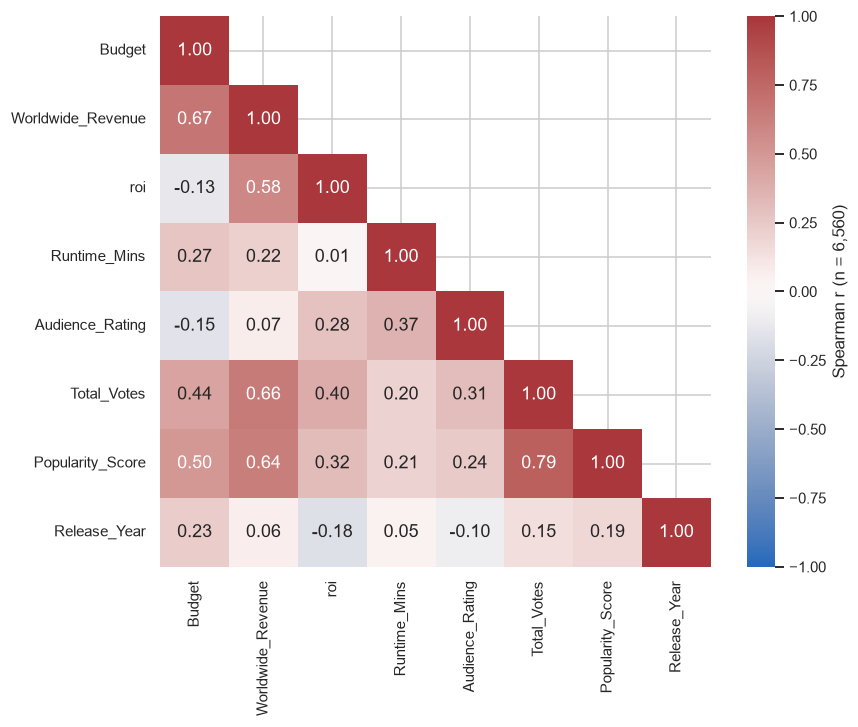

In [6]:
num_cols = ["Budget", "Worldwide_Revenue", "roi", "Runtime_Mins", "Audience_Rating",
            "Total_Votes", "Popularity_Score", "Release_Year"]
corr = fin[num_cols].astype("float64").corr(method="spearman")
stats["roi_budget_spearman"] = round(float(corr.loc["roi", "Budget"]), 3)
stats["votes_revenue_spearman"] = round(float(corr.loc["Total_Votes", "Worldwide_Revenue"]), 3)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"label": f"Spearman r (n = {len(fin):,})"}, ax=ax)
save_fig(fig, "fig3_10_corr_heatmap")
stats["rating_votes_spearman"] = round(float(corr.loc["Audience_Rating", "Total_Votes"]), 3)
stats["budget_year_spearman"] = round(float(corr.loc["Budget", "Release_Year"]), 3)
# p-values for the heatmap's headline cells (n identical for every cell)
_, p_rb = sps.spearmanr(fin["roi"], fin["Budget"])
stats["roi_budget_spearman_p"] = float(p_rb)
plt.show()

## Runtime vs rating

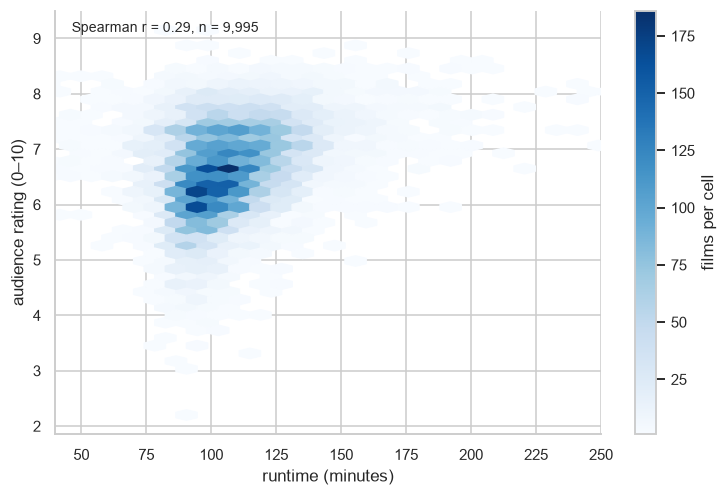

Spearman r = 0.292 (p = 2.5e-196), n = 9,995


In [7]:
rr = df.dropna(subset=["Runtime_Mins", "Audience_Rating"]).copy()
r_s3, p_s3 = sps.spearmanr(rr["Runtime_Mins"].astype("float64"), rr["Audience_Rating"])
stats.update(runtime_rating_spearman=round(float(r_s3), 3), runtime_rating_p=float(p_s3),
             runtime_rating_n=len(rr))

fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(rr["Runtime_Mins"].astype("float64"), rr["Audience_Rating"].astype("float64"),
               gridsize=45, cmap="Blues", mincnt=1)
ax.set_xlim(40, 250)
ax.set_xlabel("runtime (minutes)")
ax.set_ylabel("audience rating (0–10)")
fig.colorbar(hb, ax=ax, label="films per cell")
ax.annotate(f"Spearman r = {r_s3:.2f}, n = {len(rr):,}",
            xy=(0.03, 0.95), xycoords="axes fraction", fontsize=9)
save_fig(fig, "fig3_11_runtime_vs_rating")
plt.show()
print(f"Spearman r = {r_s3:.3f} (p = {p_s3:.1e}), n = {len(rr):,}")

## Budget and ROI by decade, in constant 2025 dollars

Deflated budgets make decades comparable; ROI needs no deflation (the
factor cancels in the ratio). Decades before 1940 have too few documented
films to plot honestly and are listed in the table instead.

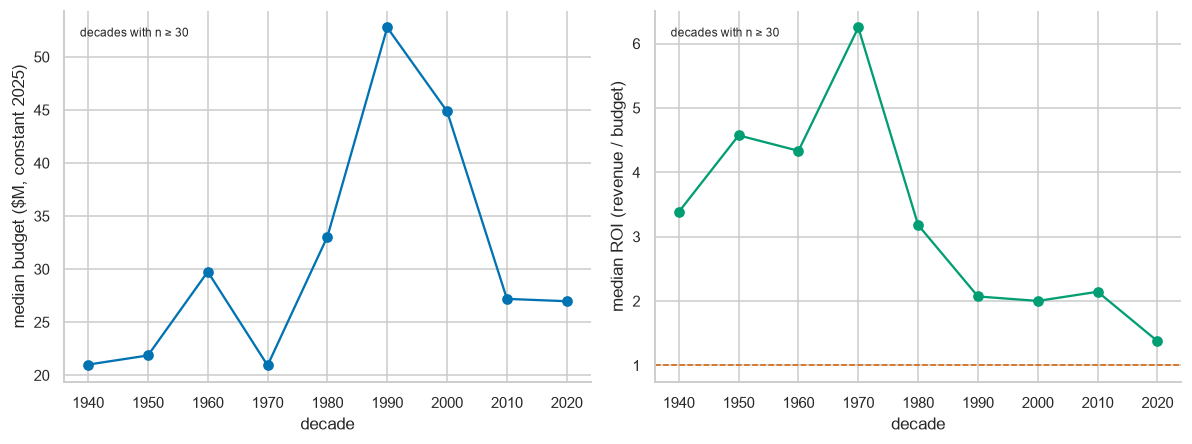

,n,median_budget_2025,median_roi
decade,,,
1910,2,7300276.05,502.27
1920,6,9075329.07,2.83
1930,26,17803870.23,2.76
1940,45,21005775.28,3.38
1950,78,21865970.22,4.57
1960,123,29755964.06,4.33
1970,217,20931716.50,6.25
1980,536,33067893.80,3.18
1990,940,52771272.12,2.07


In [8]:
d = fin.dropna(subset=["Budget_2025usd"]).copy()
d["decade"] = (d["Release_Year"].astype("float64") // 10 * 10).astype(int)
by_dec = d.groupby("decade").agg(
    n=("roi", "size"),
    median_budget_2025=("Budget_2025usd", "median"),
    median_roi=("roi", "median"),
)
by_dec_plot = by_dec[by_dec["n"] >= 30]
stats["decade_table"] = by_dec.reset_index().to_dict("records")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(by_dec_plot.index, by_dec_plot["median_budget_2025"] / 1e6, marker="o", color="C0")
axes[0].set_xlabel("decade")
axes[0].set_ylabel("median budget ($M, constant 2025)")
axes[1].plot(by_dec_plot.index, by_dec_plot["median_roi"], marker="o", color="C2")
axes[1].axhline(1, ls="--", color="C3", lw=1)
axes[1].set_xlabel("decade")
axes[1].set_ylabel("median ROI (revenue / budget)")
for ax in axes:
    ax.annotate("decades with n ≥ 30", xy=(0.03, 0.93), xycoords="axes fraction", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig3_12_decade_trends")
plt.show()

for dec in [1970, 1990, 2010, 2020]:
    stats[f"decade_{dec}_median_budget_m"] = round(float(by_dec.loc[dec, "median_budget_2025"]) / 1e6, 1)
    stats[f"decade_{dec}_median_roi"] = round(float(by_dec.loc[dec, "median_roi"]), 2)
    stats[f"decade_{dec}_n"] = int(by_dec.loc[dec, "n"])

dec_tex = by_dec.reset_index()
dec_tex = pd.DataFrame(
    {
        "decade": dec_tex["decade"].map(lambda d: f"{d}s"),
        "n": dec_tex["n"].map(fmt_int),
        "median budget (2025 \\$M)": dec_tex["median_budget_2025"].map(fmt_money_m),
        "median ROI": dec_tex["median_roi"].map(lambda v: f"{v:.2f}"),
    }
)
write_table(dec_tex, "tab3_2_decades")
by_dec.round(2)

## Chapter 1 question — which genres have the best ratio of rating to cost?

For each genre (exploded, >= 100 documented films), the median audience
rating and the median constant-2025 budget. "Value" is the median rating
per \$10M of median budget. The ratio is dominated by its denominator, so
the scatter is the more honest reading: genres up and to the left give
more rating for less money.

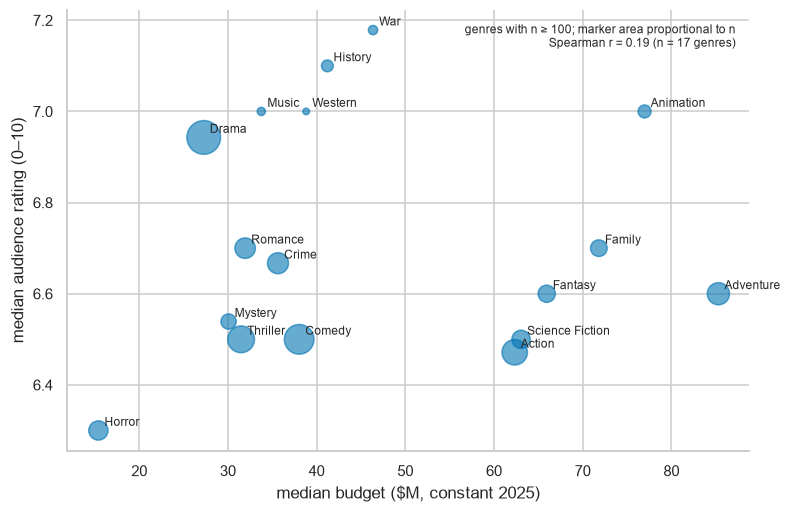

,n,median_rating,median_budget_2025,rating_per_10m
Genre,,,,
Horror,957,6.30,15394698.46,4.09
Drama,2921,6.94,27271267.98,2.55
Mystery,602,6.54,30072522.05,2.17
Romance,1083,6.70,31940109.96,2.10
Music,173,7.00,33761164.29,2.07
Thriller,1844,6.50,31481875.65,2.06
Crime,1137,6.67,35643425.14,1.87
Western,111,7.00,38817792.95,1.80
History,359,7.10,41213100.06,1.72


In [9]:
val = (
    g.groupby("Genre")
    .agg(n=("roi", "size"), median_rating=("Audience_Rating", "median"),
         median_budget_2025=("Budget_2025usd", "median"))
)
val["rating_per_10m"] = val["median_rating"] / (val["median_budget_2025"] / 1e7)
val = val.sort_values("rating_per_10m", ascending=False)
r_gv, p_gv = sps.spearmanr(val["median_budget_2025"], val["median_rating"])
stats.update(
    value_top_genre=str(val.index[0]),
    value_top_ratio=round(float(val["rating_per_10m"].iloc[0]), 2),
    value_second_genre=str(val.index[1]),
    value_bottom_genre=str(val.index[-1]),
    value_bottom_ratio=round(float(val["rating_per_10m"].iloc[-1]), 2),
    value_top_rating_genre=str(val["median_rating"].idxmax()),
    value_top_rating=round(float(val["median_rating"].max()), 2),
    genre_budget_rating_spearman=round(float(r_gv), 3),
    genre_budget_rating_p=float(p_gv),
    genre_budget_rating_n=len(val),
)

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.scatter(val["median_budget_2025"] / 1e6, val["median_rating"], s=val["n"] / 6, alpha=0.6, color="C0")
for name, r in val.iterrows():
    ax.annotate(name, (r["median_budget_2025"] / 1e6, r["median_rating"]),
                xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("median budget ($M, constant 2025)")
ax.set_ylabel("median audience rating (0–10)")
ax.annotate(f"genres with n ≥ 100; marker area proportional to n\nSpearman r = {r_gv:.2f} (n = {len(val)} genres)",
            xy=(0.98, 0.97), xycoords="axes fraction", fontsize=8, ha="right", va="top")
save_fig(fig, "fig3_13_genre_value")
plt.show()

val_tex = val.reset_index()
val_tex = pd.DataFrame(
    {
        "genre": val_tex["Genre"],
        "n": val_tex["n"].map(fmt_int),
        "median rating": val_tex["median_rating"].map(lambda v: f"{v:.2f}"),
        "median budget (2025 \\$M)": val_tex["median_budget_2025"].map(fmt_money_m),
        "rating per \\$10M": val_tex["rating_per_10m"].map(lambda v: f"{v:.2f}"),
    }
)
write_table(val_tex, "tab3_3_genre_value")
val.round(2)

## Chapter 1 question — has mid-budget profitability changed since 2000?

"Mid-budget" is fixed by convention before looking at outcomes: a
constant-2025 budget between \$20M and \$80M. Periods: 2000–09, 2010–19,
2020–25. ROI across periods is compared with Kruskal-Wallis and the
profitable share with a chi-square test. The 2020s include the pandemic
collapse of theatrical release and are flagged as such.

In [10]:
mid = fin[(fin["Budget_2025usd"] >= 20e6) & (fin["Budget_2025usd"] <= 80e6)
          & (fin["Release_Year"] >= 2000)].copy()
mid["period"] = pd.cut(mid["Release_Year"].astype("float64"), [1999, 2009, 2019, 2025],
                       labels=["2000–09", "2010–19", "2020–25"])
mid["profitable"] = mid["roi"] > 1
by_period = mid.groupby("period", observed=True).agg(
    n=("roi", "size"), median_roi=("roi", "median"), pct_profitable=("profitable", "mean"),
)
by_period["pct_profitable"] *= 100
kw_mid = sps.kruskal(*[grp["roi"].values for _, grp in mid.groupby("period", observed=True)])
chi_mid = sps.chi2_contingency(pd.crosstab(mid["period"], mid["profitable"]))
mw_mid = sps.mannwhitneyu(mid.loc[mid["period"] == "2000–09", "roi"],
                          mid.loc[mid["period"] == "2010–19", "roi"], alternative="two-sided")
stats.update(
    mid_n=len(mid),
    mid_roi_2000s=round(float(by_period.loc["2000–09", "median_roi"]), 2),
    mid_roi_2010s=round(float(by_period.loc["2010–19", "median_roi"]), 2),
    mid_roi_2020s=round(float(by_period.loc["2020–25", "median_roi"]), 2),
    mid_pct_prof_2000s=round(float(by_period.loc["2000–09", "pct_profitable"]), 1),
    mid_pct_prof_2010s=round(float(by_period.loc["2010–19", "pct_profitable"]), 1),
    mid_pct_prof_2020s=round(float(by_period.loc["2020–25", "pct_profitable"]), 1),
    mid_n_2000s=int(by_period.loc["2000–09", "n"]),
    mid_n_2010s=int(by_period.loc["2010–19", "n"]),
    mid_n_2020s=int(by_period.loc["2020–25", "n"]),
    mid_kruskal_p=float(kw_mid.pvalue),
    mid_chi2_p=float(chi_mid.pvalue),
    mid_2000s_vs_2010s_p=float(mw_mid.pvalue),
)
mid_tex = by_period.reset_index()
mid_tex = pd.DataFrame(
    {
        "period": mid_tex["period"].astype(str).str.replace("–", "--", regex=False),
        "n": mid_tex["n"].map(fmt_int),
        "median ROI": mid_tex["median_roi"].map(lambda v: f"{v:.2f}"),
        "% profitable": mid_tex["pct_profitable"].map(lambda v: f"{v:.1f}"),
    }
)
write_table(mid_tex, "tab3_4_mid_budget")
print(f"Kruskal-Wallis on ROI across periods: p = {kw_mid.pvalue:.2e}")
print(f"chi-square on profitable share:       p = {chi_mid.pvalue:.2e}")
print(f"2000s vs 2010s only (Mann-Whitney):   p = {mw_mid.pvalue:.3f}")
by_period.round(2)

Kruskal-Wallis on ROI across periods: p = 2.47e-10
chi-square on profitable share:       p = 3.91e-10
2000s vs 2010s only (Mann-Whitney):   p = 0.879


,n,median_roi,pct_profitable
period,,,
2000–09,785,1.78,70.45
2010–19,829,1.89,69.96
2020–25,279,1.00,50.18


In [11]:
out = write_stats("ch03_multivariate", stats)
print(f"{len(stats)} statistics written to {out.relative_to(ROOT)}")

82 statistics written to report\stats\ch03_multivariate.json


## What Chapter 3 found (carried to the report)

- Budget and revenue are strongly associated on the log-log scale, but a
  large minority of films sit below even the production-budget break-even
  line — before marketing costs.
- Genre ROI differences are inseparable from genre budget differences:
  the high-ROI genres are the cheap ones. Mean ROI is uninformative
  without the median beside it.
- Rating and revenue are only weakly rank-correlated: commercial and
  critical success are substantially different outcomes.
- Genre "value" (rating per dollar) is led by the low-budget genres,
  while across genres median budget and median rating are essentially
  unrelated. Mid-budget profitability was flat from the 2000s to the
  2010s and fell in 2020–25. Exact figures are in the stats JSON and
  quoted in Chapter 6.
- Release month matters (Kruskal-Wallis p ≈ 10⁻⁴⁴): June, July and
  December lead; September and October are the dumping ground, with a
  June median revenue nearly 3× September's.
- Genre ROI contradicts folklore: Animation, Music and Family top the
  medians; horror's reputation rests on two micro-budget outliers that
  explode its mean.
- By decade, median real budgets peaked in the 1990s (~\$53M in 2025
  dollars) and have fallen since, while median ROI has slid from ~6 in
  the 1970s to 1.38 in the 2020s — the typical documented film now
  barely recoups its production budget from worldwide gross.